In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv('apps.csv')
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19.0,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14.0,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25.0,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9659 entries, 0 to 9658
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             9659 non-null   object 
 1   Category        9659 non-null   object 
 2   Rating          8196 non-null   float64
 3   Reviews         9659 non-null   int64  
 4   Size            8432 non-null   float64
 5   Installs        9659 non-null   object 
 6   Type            9659 non-null   object 
 7   Price           9659 non-null   object 
 8   Content Rating  9659 non-null   object 
 9   Genres          9659 non-null   object 
 10  Last Updated    9659 non-null   object 
 11  Current Ver     9651 non-null   object 
 12  Android Ver     9657 non-null   object 
dtypes: float64(2), int64(1), object(10)
memory usage: 981.1+ KB


In [12]:
df = df.dropna(subset=['Rating'])

In [13]:
df['Installs'] = df['Installs'].str.replace(',', '')
df['Installs'] = df['Installs'].str.replace('+', '')
df['Installs'] = df['Installs'].astype(int)

In [14]:
df['Price'] = df['Price'].str.replace('$', '')
df['Price'] = df['Price'].astype(float)

In [15]:
df['Reviews'] = df['Reviews'].astype(int)

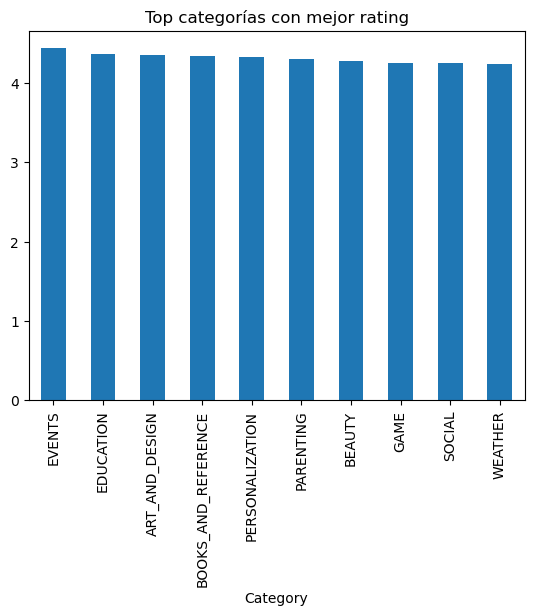

In [16]:
category_rating = df.groupby('Category')['Rating'].mean().sort_values(ascending=False)

plt.figure()
category_rating.head(10).plot(kind='bar')
plt.title('Top categorías con mejor rating')
plt.show()

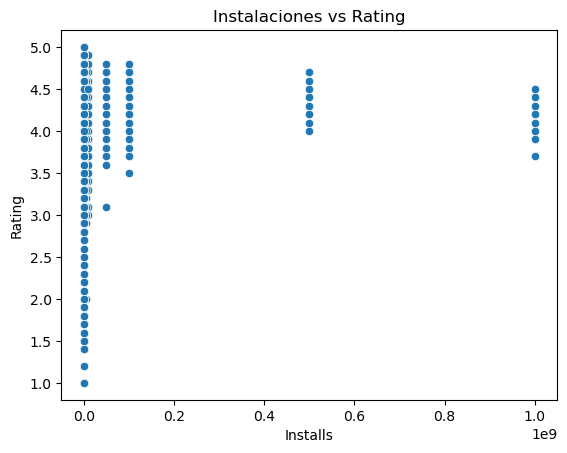

In [17]:
plt.figure()
sns.scatterplot(x='Installs', y='Rating', data=df)
plt.title('Instalaciones vs Rating')
plt.show()

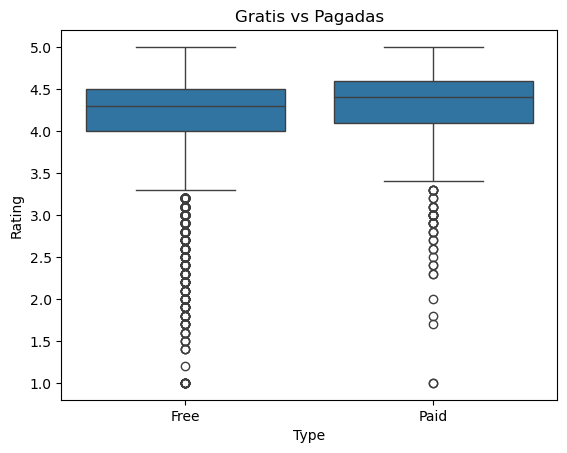

In [18]:
plt.figure()
sns.boxplot(x='Type', y='Rating', data=df)
plt.title('Gratis vs Pagadas')
plt.show()

In [20]:
df['Size'] = df['Size'].astype(str)
df['Size'] = df['Size'].str.replace('M', '')
df['Size'] = df['Size'].str.replace('k', '')
df['Size'] = df['Size'].replace('Varies with device', None)
df['Size'] = pd.to_numeric(df['Size'], errors='coerce')

In [21]:
top_apps = df.sort_values(by='Installs', ascending=False).head(10)
top_apps[['App', 'Installs']]

,App,Installs
2191,Google Photos,1000000000
2002,Facebook,1000000000
152,Google Play Books,1000000000
701,Google Play Games,1000000000
2012,Google+,1000000000
2003,Instagram,1000000000
1356,Subway Surfers,1000000000
2977,Google News,1000000000
304,Gmail,1000000000
302,Google Chrome: Fast & Secure,1000000000


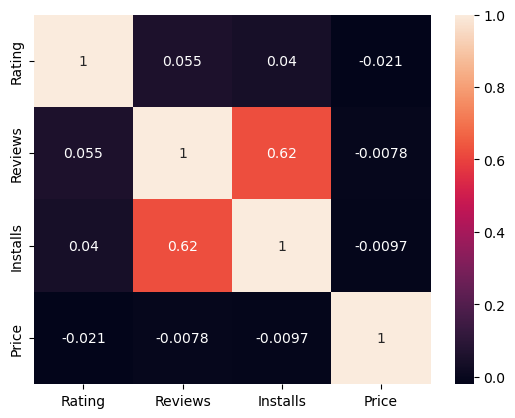

In [22]:
plt.figure()
sns.heatmap(df[['Rating', 'Reviews', 'Installs', 'Price']].corr(), annot=True)
plt.show()

In [23]:
# Estadísticas generales
df.describe()

,Rating,Reviews,Size,Installs,Price
count,8196.000000,8.196000e+03,7027.000000,8.196000e+03,8196.000000
mean,4.173243,2.552515e+05,21.754490,9.165090e+06,1.037884
std,0.536625,1.985594e+06,22.726446,5.825087e+07,16.857882
min,1.000000,1.000000e+00,0.000000,1.000000e+00,0.000000
25%,4.000000,1.260000e+02,4.900000,1.000000e+04,0.000000
50%,4.300000,3.004000e+03,13.000000,1.000000e+05,0.000000
75%,4.500000,4.381300e+04,31.000000,1.000000e+06,0.000000
max,5.000000,7.815831e+07,100.000000,1.000000e+09,400.000000


In [24]:
df.groupby('Category')['Rating'].mean().sort_values(ascending=False)

Category
EVENTS                 4.435556
EDUCATION              4.364407
ART_AND_DESIGN         4.357377
BOOKS_AND_REFERENCE    4.344970
PERSONALIZATION        4.332215
PARENTING              4.300000
BEAUTY                 4.278571
GAME                   4.247368
SOCIAL                 4.247291
WEATHER                4.243056
HEALTH_AND_FITNESS     4.243033
SHOPPING               4.230000
SPORTS                 4.216154
AUTO_AND_VEHICLES      4.190411
PRODUCTIVITY           4.183389
COMICS                 4.181481
FAMILY                 4.179664
LIBRARIES_AND_DEMO     4.178125
FOOD_AND_DRINK         4.172340
MEDICAL                4.166552
PHOTOGRAPHY            4.157414
HOUSE_AND_HOME         4.150000
ENTERTAINMENT          4.135294
NEWS_AND_MAGAZINES     4.121569
COMMUNICATION          4.121484
FINANCE                4.115563
BUSINESS               4.098479
LIFESTYLE              4.093355
TRAVEL_AND_LOCAL       4.069519
VIDEO_PLAYERS          4.044595
TOOLS                  4.039554

In [25]:
df.groupby('Price')['Rating'].mean().sort_values(ascending=False)

Price
1.75      5.0
3.04      5.0
2.50      4.8
2.59      4.7
3.90      4.7
         ... 
2.56      3.4
15.46     3.4
6.49      3.4
379.99    2.9
4.59      2.0
Name: Rating, Length: 73, dtype: float64

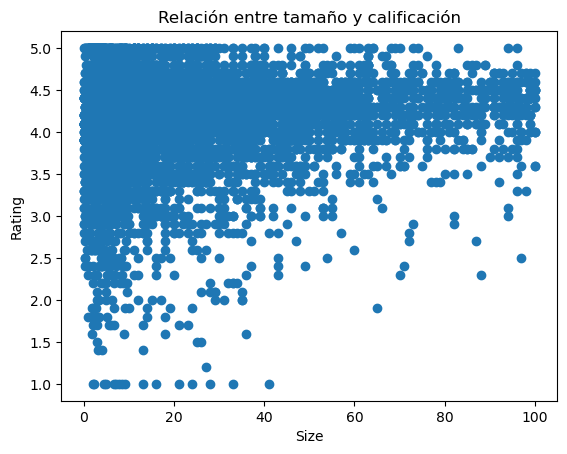

In [26]:
import matplotlib.pyplot as plt

plt.scatter(df['Size'], df['Rating'])
plt.xlabel('Size')
plt.ylabel('Rating')
plt.title('Relación entre tamaño y calificación')
plt.show()

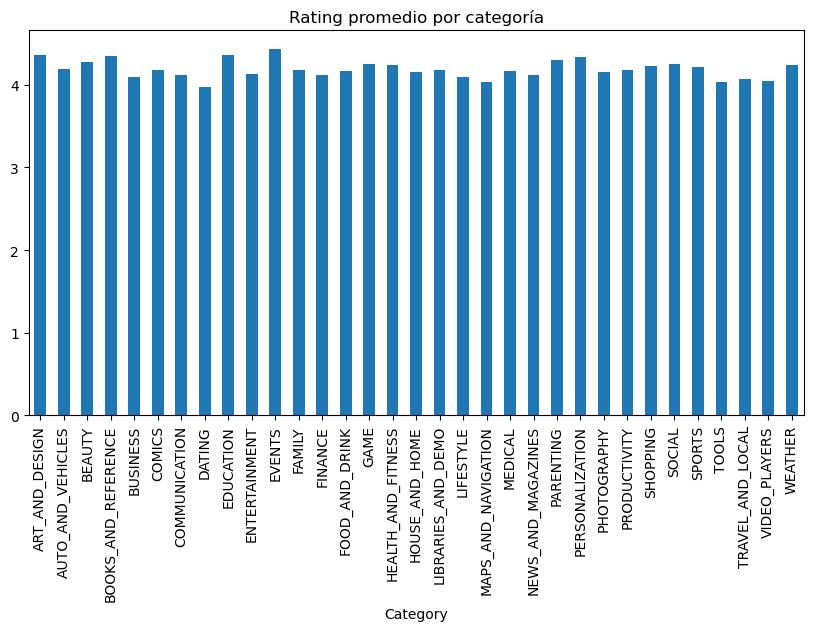

In [27]:
df.groupby('Category')['Rating'].mean().plot(kind='bar', figsize=(10,5))
plt.title('Rating promedio por categoría')
plt.show()

In [ ]:
#Se observa que ciertas categorías presentan mejores calificaciones promedio, lo que indica una mayor aceptación por parte de los usuarios. Asimismo, el precio no parece influir significativamente en la calificación, ya que muchas aplicaciones gratuitas tienen altos ratings. En cuanto al tamaño, no se observa una relación directa fuerte con la calificación.